# HuRI vs Lit-BM: does a systematically screened interactome differ topologically from a literature-curated one?
**CB 5313 – Systems Biology & Network Modeling · Topic 5 · Primary paper: Luck et al. (2020), *Nature* 580:402–408**

**Question.** HuRI was built by screening protein pairs systematically (yeast two-hybrid, Y2H). Lit-BM is curated from hypothesis-driven studies that favour well-studied genes. Do the two binary PPI networks differ in global topology, and which differences are more than what their degree sequences alone would produce?

**Data.** `HuRI.tsv` (HI-III-20) and `Lit-BM.tsv` from the CCSB Interactome Atlas (CC BY 4.0). Run `python src/download_data.py` to fetch them (not committed to git).

**Changes beyond a tutorial.**
1. Lit-BM as a comparator network (not HuRI alone).
2. Degree-preserving rewiring null with fold-changes and z-scores.
3. Parameter sweeps: fraction of nodes removed (hub vs random) and k-core threshold.
4. Hub-overlap check between the two networks.
5. Density-matched control: HuRI subsampled to Lit-BM's size, to test whether the robustness gap is just a density effect.

**AI-use disclosure.** Code scaffold and the cell notes were drafted with Claude (Anthropic) and then run and checked on the real data. The biological interpretation in the final section must be rewritten in my own words before submission.

**Mapping to the project brief (change beyond the tutorial).**
- *A different dataset:* Lit-BM, an independently curated literature network, is analysed beside HuRI and compared with it directly.
- *A parameter sweep with its effect on the result:* node-removal fraction (0–30%, hub vs random), k-core threshold (1–10), and a density-matched subsampling control. Each sweep's effect is interpreted in the observation notes and the final results section.

## Expectations (written before running the analysis)
*Edit these in your own words, so you can answer "What did you expect before your change?"*
- **E1.** Hub identities will differ between networks: Luck et al. report that in literature-curated networks degree tracks how much a protein is studied, but not in HuRI.
- **E2.** Both networks will show more clustering than a degree-preserving null, and be disassortative.
- **E3.** Lit-BM will fragment faster under hub removal, but Lit-BM is also ~4× sparser, so part of that gap may just be density (hence the density-matched control).

In [1]:
# --- Setup -------------------------------------------------------------------
import random, pathlib
import numpy as np, pandas as pd, igraph as ig
from scipy.stats import spearmanr
import matplotlib.pyplot as plt

random.seed(0); np.random.seed(0)                      # fixed seeds -> reproducible results
DATA = pathlib.Path("data"); OUT = pathlib.Path("results"); OUT.mkdir(exist_ok=True)
print("python-igraph version:", ig.__version__)

python-igraph version: 1.0.0


**Observation:** Libraries import without error (python-igraph, numpy, pandas, scipy, matplotlib). Seeds are fixed, so every table below is reproducible. The `results/` folder is created for figures and tables.

In [2]:
# --- Load raw edge lists --------------------------------------------------------
# Each file: two columns of Ensembl gene IDs (one interacting pair per row), no header.
def load_raw(path):
    if not path.exists():
        raise FileNotFoundError(f"{path} missing - run: python src/download_data.py")
    return pd.read_csv(path, sep="\t", header=None, usecols=[0, 1], dtype=str)

raw = {"HuRI": load_raw(DATA/"HuRI.tsv"), "Lit-BM": load_raw(DATA/"Lit-BM.tsv")}
for k, df in raw.items():
    loops = (df[0] == df[1]).sum()                                        # protein 'interacting' with itself
    uniq = {tuple(sorted(e)) for e in df.itertuples(index=False, name=None)}  # A-B and B-A count once
    print(f"{k}: rows={len(df)}  self-loops={loops}  unique undirected pairs={len(uniq)}  "
          f"proteins={pd.unique(df.values.ravel()).size}")
print(raw["HuRI"].head(3))

HuRI: rows=52548  self-loops=480  unique undirected pairs=52548  proteins=8272
Lit-BM: rows=13441  self-loops=683  unique undirected pairs=13441  proteins=6047
                 0                1
0  ENSG00000000005  ENSG00000061656
1  ENSG00000000005  ENSG00000099968
2  ENSG00000000005  ENSG00000104765


**Observation:** Reads the two edge lists (Ensembl gene-ID pairs, no header). HuRI has **52,548 rows** (480 self-interactions, 8,272 proteins). Lit-BM has **13,441 rows** (683 self-interactions, 6,047 proteins). No duplicated pairs exist in either file. Lit-BM has a larger self-loop share (5.1% vs 0.9%), so the cleaning step matters more for it.

In [3]:
# --- Build simple undirected graphs + sanity check against published sizes ----------
def load_network(df):
    """Raw edge table -> simple undirected igraph Graph (self-loops and duplicate pairs removed)."""
    df = df[df[0] != df[1]]
    edges = sorted({tuple(sorted(e)) for e in df.itertuples(index=False, name=None)})
    return ig.Graph.TupleList(edges, directed=False).simplify()

# Published edge counts (paper / download page) INCLUDE self-interactions, so compare raw rows to them.
EXPECTED_EDGES = {"HuRI": 52569, "Lit-BM": 13441}
nets = {k: load_network(v) for k, v in raw.items()}
for k, g in nets.items():
    exp = EXPECTED_EDGES[k]
    print(f"{k:7s} raw rows (incl. self-loops) = {len(raw[k])} | published = {exp} | diff {100*(len(raw[k])-exp)/exp:+.2f}%")
    print(f"{k:7s} analysed graph (self-loops removed): nodes={g.vcount()}, edges={g.ecount()}")

HuRI    raw rows (incl. self-loops) = 52548 | published = 52569 | diff -0.04%
HuRI    analysed graph (self-loops removed): nodes=8245, edges=52068
Lit-BM  raw rows (incl. self-loops) = 13441 | published = 13441 | diff +0.00%
Lit-BM  analysed graph (self-loops removed): nodes=5956, edges=12758


**Observation:** Self-loops are removed because a protein binding itself is not an edge between two proteins. Raw row counts match the published sizes (HuRI 52,548 vs 52,569, −0.04%; Lit-BM 13,441 vs 13,441), which confirms these are the right files. The analysed graphs are **HuRI: 8,245 nodes / 52,068 edges** and **Lit-BM: 5,956 nodes / 12,758 edges**. 27 HuRI and 91 Lit-BM proteins interacted only with themselves, so they drop out.

In [4]:
# --- Global topology metrics ----------------------------------------------------
def lcc(g):
    """Largest connected component."""
    return g.connected_components().giant()

def mean_path_length(g, n_src=300, seed=0):
    """Mean shortest path in the largest component, estimated from 300 random source nodes (exact would be slow)."""
    rnd = random.Random(seed); G = lcc(g)
    src = rnd.sample(range(G.vcount()), min(n_src, G.vcount()))
    d = np.array(G.distances(source=src))
    return d[d > 0].mean()                                  # d==0 is a node to itself

def metrics(g):
    deg = np.array(g.degree())
    return {"nodes": g.vcount(), "edges": g.ecount(),
            "mean_degree": deg.mean(), "median_degree": np.median(deg), "max_degree": deg.max(),
            "lcc_fraction": lcc(g).vcount() / g.vcount(),
            "n_components": len(g.connected_components()),
            "global_clustering": g.transitivity_undirected(),        # 3*triangles / connected triples
            "avg_local_clustering": g.transitivity_avglocal_undirected(mode="zero"),
            "degree_assortativity": g.assortativity_degree(),        # <0: hubs link to low-degree nodes
            "mean_path_length_lcc": mean_path_length(g)}

obs = pd.DataFrame({k: metrics(g) for k, g in nets.items()})
obs.round(4)

,HuRI,Lit-BM
nodes,8245.0000,5956.0000
edges,52068.0000,12758.0000
mean_degree,12.6302,4.2841
median_degree,4.0000,2.0000
max_degree,498.0000,413.0000
lcc_fraction,0.9884,0.9372
n_components,45.0000,157.0000
global_clustering,0.0559,0.0200
avg_local_clustering,0.0594,0.0627
degree_assortativity,-0.1179,-0.0919


**Observation:** HuRI has about **4× more edges** than Lit-BM (52,068 vs 12,758) and is denser (mean degree 12.6 vs 4.3; median 4 vs 2). It is also better connected: 98.8% of proteins are in the largest component (45 components in total) vs 93.7% for Lit-BM (157 components), and its mean path length is shorter (3.87 vs 4.72). Global clustering is higher in HuRI (0.056 vs 0.020), but average local clustering is about equal (0.059 vs 0.063), so the two clustering measures disagree. Both networks are disassortative (−0.12 and −0.09), meaning hubs tend to bind low-degree proteins.

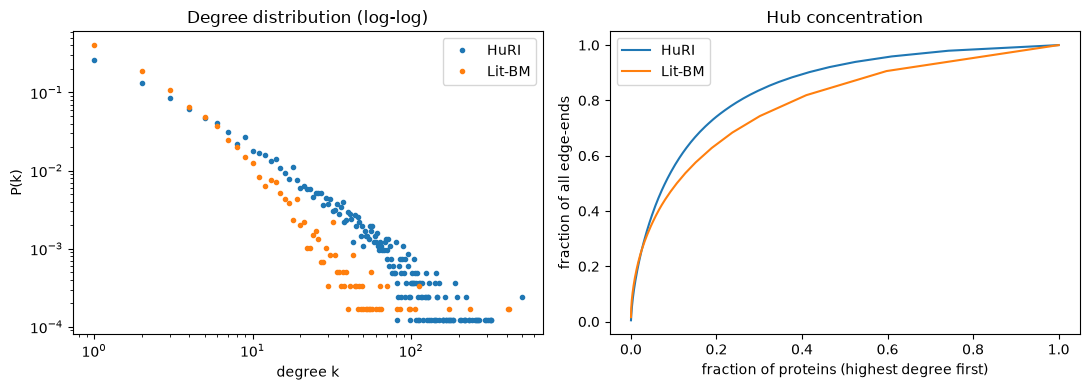

HuRI: degree-1 proteins = 26.3% | top 1% of proteins hold 14.4% of edge-ends | top 10 degrees = [498, 498, 319, 318, 313, 304, 296, 292, 267, 264]
Lit-BM: degree-1 proteins = 40.4% | top 1% of proteins hold 16.4% of edge-ends | top 10 degrees = [413, 407, 234, 173, 112, 112, 106, 98, 97, 85]


In [5]:
# --- Degree distribution and hub concentration ------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for k, g in nets.items():
    d = np.array(g.degree()); v, c = np.unique(d, return_counts=True)
    ax[0].loglog(v, c / c.sum(), "o", ms=3, label=k)                      # P(k) on log-log axes
    s = np.sort(d)[::-1]                                                  # highest degree first
    ax[1].plot(np.arange(1, len(s) + 1) / len(s), np.cumsum(s) / s.sum(), label=k)
ax[0].set(xlabel="degree k", ylabel="P(k)", title="Degree distribution (log-log)"); ax[0].legend()
ax[1].set(xlabel="fraction of proteins (highest degree first)", ylabel="fraction of all edge-ends", title="Hub concentration"); ax[1].legend()
plt.tight_layout(); plt.savefig(OUT/"degree_distribution.png", dpi=200); plt.show()

for k, g in nets.items():
    d = np.array(g.degree()); s = np.sort(d)[::-1]
    print(f"{k}: degree-1 proteins = {100*(d==1).mean():.1f}% | top 1% of proteins hold "
          f"{100*s[:max(1, len(s)//100)].sum()/s.sum():.1f}% of edge-ends | top 10 degrees = {s[:10].tolist()}")

**Observation:** Left: both degree distributions are heavy-tailed on log-log axes (many low-degree proteins, a few hubs). Right: the share of edge-ends held by the top-degree proteins. Lit-BM has more degree-1 proteins (**40.4%** vs 26.3%). The top 1% of proteins hold a similar share in both (14.4% HuRI, 16.4% Lit-BM). HuRI has many large hubs of similar size (498, 498, 319, 318, ...). Lit-BM has two extreme hubs (413, 407) followed by a sharp drop (234, 173, 112, ...). That is consistent with literature data concentrating on a few heavily studied proteins, but this cell does not test it directly.

In [6]:
# --- Degree-preserving null model -----------------------------------------------------
# Rewire edges (10*E swaps) so every protein keeps its degree but partners are randomised.
# Anything left over vs the null is structure NOT explained by the degree sequence alone.
def null_stats(g, n_null=30, seed=1):
    random.seed(seed); cl, asr = [], []
    for _ in range(n_null):
        h = g.copy(); h.rewire(n=10 * g.ecount())
        cl.append(h.transitivity_undirected()); asr.append(h.assortativity_degree())
    return np.array(cl), np.array(asr)

rows = {}
for k, g in nets.items():
    cl, asr = null_stats(g); o = obs[k]
    rows[k] = {"clustering_obs": o["global_clustering"], "clustering_null_mean": cl.mean(), "clustering_null_sd": cl.std(),
               "clustering_z": (o["global_clustering"] - cl.mean()) / (cl.std() + 1e-12),
               "clustering_fold_vs_null": o["global_clustering"] / cl.mean(),
               "assort_obs": o["degree_assortativity"], "assort_null_mean": asr.mean(), "assort_null_sd": asr.std(),
               "assort_z": (o["degree_assortativity"] - asr.mean()) / (asr.std() + 1e-12)}
null_table = pd.DataFrame(rows); null_table.round(4)

,HuRI,Lit-BM
clustering_obs,0.0559,0.0200
clustering_null_mean,0.0319,0.0125
clustering_null_sd,0.0004,0.0005
clustering_z,62.3956,14.3823
clustering_fold_vs_null,1.7499,1.6010
assort_obs,-0.1179,-0.0919
assort_null_mean,-0.0453,-0.0580
assort_null_sd,0.0033,0.0017
assort_z,-22.2001,-20.3263


**Observation:** Compares observed clustering and assortativity with 30 degree-preserving rewired copies of each network. Clustering is **1.75× the null in HuRI** (0.056 vs 0.032) and **1.60× in Lit-BM** (0.020 vs 0.0125), so both have more triangles than degree alone explains. Both are also **more disassortative than the null** (HuRI −0.118 vs −0.045; Lit-BM −0.092 vs −0.058). The z-scores are very large (62, 14, −22, −20) because the null spread is tiny with only 30 replicates, so rely on the fold-differences rather than the z-values.

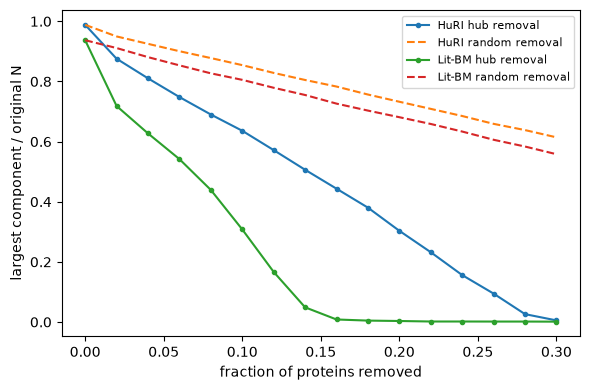

,HuRI hubs,HuRI random,Lit-BM hubs,Lit-BM random
0.00,0.988,0.988,0.937,0.937
0.06,0.748,0.901,0.542,0.854
0.10,0.636,0.854,0.308,0.805
0.20,0.303,0.733,0.003,0.681
0.30,0.005,0.614,0.001,0.558


In [7]:
# --- Robustness sweep: remove 0-30% of proteins (hubs first vs random) ---------------------
fracs = np.round(np.arange(0, 0.31, 0.02), 2)

def robustness(g, mode, seed=0):
    """Size of the largest component (as fraction of the ORIGINAL node count) after removing a fraction of nodes.
    mode='hubs': highest ORIGINAL degree first (static attack, ties broken deterministically); 'random': random order."""
    n = g.vcount()
    if mode == "hubs":
        order = np.argsort(-np.array(g.degree()), kind="stable")          # stable sort -> reproducible with ties
    else:
        order = random.Random(seed).sample(range(n), n)
    res = []
    for f in fracs:
        h = g.copy(); h.delete_vertices([int(i) for i in order[:int(f * n)]])
        res.append(lcc(h).vcount() / n if h.vcount() else 0)
    return res

rob = {(k, m): robustness(g, m) for k, g in nets.items() for m in ("hubs", "random")}
rob_df = pd.DataFrame(rob, index=fracs); rob_df.columns = [f"{a} {b}" for a, b in rob_df.columns]

plt.figure(figsize=(6, 4))
for k in nets:
    plt.plot(fracs, rob_df[f"{k} hubs"], "-o", ms=3, label=f"{k} hub removal")
    plt.plot(fracs, rob_df[f"{k} random"], "--", label=f"{k} random removal")
plt.xlabel("fraction of proteins removed"); plt.ylabel("largest component / original N"); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT/"robustness.png", dpi=200); plt.show()
rob_df.loc[[0.0, 0.06, 0.1, 0.2, 0.3]].round(3)

**Observation:** Removes the highest-degree proteins (targeted attack) or random proteins and tracks the largest connected component. Random removal affects both networks similarly (at 30% removed: 61% HuRI, 56% Lit-BM). Hub removal differs a lot: at 10% removed the largest component keeps **63.6% in HuRI vs 30.8% in Lit-BM**, and at 20% it keeps 30.3% vs **0.3%**. Lit-BM fragments much earlier. The next cell checks whether this is only because Lit-BM is sparser. Hubs are ranked by original degree (not recomputed after each removal), with ties broken deterministically.

In [8]:
# --- Control for density: subsample HuRI down to Lit-BM's number of edges -----------------------
# Lit-BM is ~4x sparser than HuRI. If a thinned-out HuRI also fragments quickly, the robustness gap is a density effect.
m_litbm = nets["Lit-BM"].ecount(); n_rep = 10
sub_rows, sub_rob = [], []
for s in range(n_rep):
    idx = random.Random(s).sample(range(nets["HuRI"].ecount()), m_litbm)        # keep m random HuRI edges
    h = nets["HuRI"].subgraph_edges(idx, delete_vertices=True)
    d = np.array(h.degree())
    sub_rows.append({"nodes": h.vcount(), "mean_degree": d.mean(), "degree1_pct": 100 * (d == 1).mean(),
                     "lcc_fraction": lcc(h).vcount() / h.vcount(), "global_clustering": h.transitivity_undirected()})
    sub_rob.append(robustness(h, "hubs"))
sub = pd.DataFrame(sub_rows)
sub_curve = pd.DataFrame(sub_rob, columns=fracs)
control = pd.DataFrame({"HuRI subsampled (mean)": sub.mean(), "HuRI subsampled (sd)": sub.std(),
                        "Lit-BM": [nets["Lit-BM"].vcount(), obs.loc["mean_degree", "Lit-BM"],
                                   100 * (np.array(nets["Lit-BM"].degree()) == 1).mean(),
                                   obs.loc["lcc_fraction", "Lit-BM"], obs.loc["global_clustering", "Lit-BM"]]})
print(control.round(4))
print("\nHub-removal LCC (fraction of own N):")
print(pd.DataFrame({"HuRI subsampled mean": sub_curve.mean(), "HuRI subsampled sd": sub_curve.std(),
                    "Lit-BM": rob_df["Lit-BM hubs"], "HuRI full": rob_df["HuRI hubs"]}).loc[[0.0, 0.06, 0.1, 0.2, 0.3]].round(3))

                   HuRI subsampled (mean)  HuRI subsampled (sd)     Lit-BM
nodes                           5255.8000               41.1145  5956.0000
mean_degree                        4.8551                0.0380     4.2841
degree1_pct                       38.3341                0.4907    40.4130
lcc_fraction                       0.9455                0.0059     0.9372
global_clustering                  0.0139                0.0007     0.0200

Hub-removal LCC (fraction of own N):
      HuRI subsampled mean  HuRI subsampled sd  Lit-BM  HuRI full
0.00                 0.946               0.006   0.937      0.988
0.06                 0.655               0.005   0.542      0.748
0.10                 0.501               0.009   0.308      0.636
0.20                 0.013               0.006   0.003      0.303
0.30                 0.002               0.000   0.001      0.005


**Observation:** Density control. Ten random subsamples of HuRI are thinned to Lit-BM's 12,758 edges. Thinned HuRI looks similar to Lit-BM in basic structure (mean degree 4.9 vs 4.3; 38% vs 40% degree-1 proteins; largest component 94.6% vs 93.7%). Under hub removal the gap **shrinks but does not vanish**. At 10% removed, thinned HuRI keeps 50.1% (±0.9%), compared with 30.8% for Lit-BM and 63.6% for full HuRI. At 20% both thinned HuRI (1.3%) and Lit-BM (0.3%) have collapsed. So most of the robustness difference is a density effect, and Lit-BM is somewhat more fragile than a density-matched HuRI at low removal fractions (6–10%). Thinned HuRI also has lower global clustering than Lit-BM (0.014 vs 0.020).

In [9]:
# --- k-core sweep ---------------------------------------------------------------------------
# k-core = subnetwork where every protein has >= k neighbours inside it (repeatedly peeling low-degree proteins).
def kcore_table(g, ks=(1, 2, 3, 4, 5, 6, 8, 10)):
    cn = np.array(g.coreness()); return {k: int((cn >= k).sum()) for k in ks}

kc = pd.DataFrame({k: kcore_table(g) for k, g in nets.items()}); kc.index.name = "k-core"
kc["HuRI %"] = (100 * kc["HuRI"] / nets["HuRI"].vcount()).round(1)
kc["Lit-BM %"] = (100 * kc["Lit-BM"] / nets["Lit-BM"].vcount()).round(1)
print("max coreness:", {k: max(g.coreness()) for k, g in nets.items()})

# Is the dense 10-core one connected module or several pieces?
for k, g in nets.items():
    core = g.subgraph([i for i, c in enumerate(g.coreness()) if c >= 10])
    comps = sorted(core.connected_components().sizes(), reverse=True)
    print(f"{k} 10-core: {core.vcount()} proteins, {core.ecount()} edges, component sizes = {comps[:5]}")
kc

max coreness: {'HuRI': 27, 'Lit-BM': 14}
HuRI 10-core: 2029 proteins, 33432 edges, component sizes = [2029]
Lit-BM 10-core: 67 proteins, 593 edges, component sizes = [67]


,HuRI,Lit-BM,HuRI %,Lit-BM %
k-core,,,,
1,8245,5956,100.0,100.0
2,5978,3317,72.5,55.7
3,4835,1977,58.6,33.2
4,4071,1142,49.4,19.2
5,3530,717,42.8,12.0
6,3103,382,37.6,6.4
8,2466,67,29.9,1.1
10,2029,67,24.6,1.1


**Observation:** A k-core keeps only proteins with at least k neighbours inside the remaining subnetwork. HuRI has a deeper core (maximum coreness **27 vs 14**), and 24.6% of HuRI proteins are in the 10-core compared with **1.1% (67 proteins) of Lit-BM**. Each 10-core is a single connected piece. HuRI's has 2,029 proteins and 33,432 edges (density about 1.6%). Lit-BM's has 67 proteins and 593 edges (density about 27%), so Lit-BM's dense part is a small, very tightly connected group, while HuRI's dense part is large and loosely connected. Which proteins make up that 67-protein group was not examined here.

proteins: HuRI=8245  Lit-BM=5956  shared=3176
interactions shared: 602 = 1.2% of HuRI, 4.7% of Lit-BM
Spearman degree(HuRI) vs degree(Lit-BM) on shared proteins: rho=0.056, p=0.0016
overlap of top-50 hubs: 1 of 50


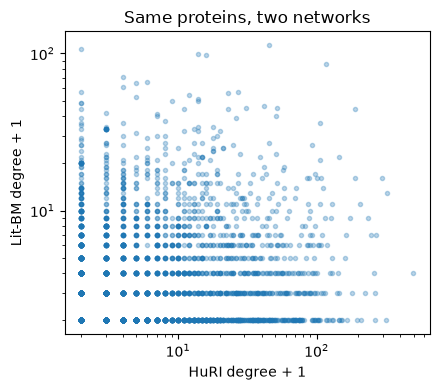

In [10]:
# --- Direct comparison of the two networks --------------------------------------------------------
name_h, name_l = nets["HuRI"].vs["name"], nets["Lit-BM"].vs["name"]
ids_h, ids_l = set(name_h), set(name_l)
e_h = {tuple(sorted((name_h[a], name_h[b]))) for a, b in nets["HuRI"].get_edgelist()}
e_l = {tuple(sorted((name_l[a], name_l[b]))) for a, b in nets["Lit-BM"].get_edgelist()}
shared_e = e_h & e_l
print(f"proteins: HuRI={len(ids_h)}  Lit-BM={len(ids_l)}  shared={len(ids_h & ids_l)}")
print(f"interactions shared: {len(shared_e)} = {100*len(shared_e)/len(e_h):.1f}% of HuRI, {100*len(shared_e)/len(e_l):.1f}% of Lit-BM")

# Do the same proteins have similar degree in both networks?
dh = dict(zip(name_h, nets["HuRI"].degree())); dl = dict(zip(name_l, nets["Lit-BM"].degree()))
both = sorted(ids_h & ids_l)
x = [dh[p] for p in both]; y = [dl[p] for p in both]
rho, p = spearmanr(x, y)
print(f"Spearman degree(HuRI) vs degree(Lit-BM) on shared proteins: rho={rho:.3f}, p={p:.2g}")
top = lambda d, n=50: set(sorted(d, key=d.get, reverse=True)[:n])
print("overlap of top-50 hubs:", len(top(dh) & top(dl)), "of 50")

plt.figure(figsize=(4.5, 4)); plt.loglog(np.array(x) + 1, np.array(y) + 1, ".", alpha=.3)
plt.xlabel("HuRI degree + 1"); plt.ylabel("Lit-BM degree + 1"); plt.title("Same proteins, two networks"); plt.tight_layout()
plt.savefig(OUT/"degree_scatter.png", dpi=200); plt.show()

**Observation:** The two networks share **3,176 proteins** but only **602 interactions** (1.2% of HuRI, 4.7% of Lit-BM). On the shared proteins, degree in HuRI and degree in Lit-BM are almost uncorrelated (Spearman ρ = 0.056, p = 0.0016, detectable but very weak), and only **1 of the top-50 hubs** is the same in both. The scatter plot shows the same pattern. This is in line with the paper's statement that literature-curated degree is shaped by factors such as how much a protein has been studied. This cell cannot prove that, because it needs publication counts per gene.

In [11]:
# --- Save tables for the report / slides ------------------------------------------------------------
summary = pd.concat([obs.round(4), null_table.round(4)])
summary.to_csv(OUT/"summary_metrics.csv"); rob_df.to_csv(OUT/"robustness.csv"); kc.to_csv(OUT/"kcore_sweep.csv")
control.round(4).to_csv(OUT/"density_control.csv")
print("saved:", sorted(p.name for p in OUT.iterdir()))

saved: ['degree_distribution.png', 'degree_scatter.png', 'density_control.csv', 'kcore_sweep.csv', 'robustness.csv', 'robustness.png', 'summary_metrics.csv']


**Observation:** Saves the summary metrics, robustness curves, k-core table and density-control table to `results/`, beside the figures, for use in the README and slides.

## Results and interpretation (draft: rewrite in your own words)
**What was found.**
1. HuRI is ~4× larger, denser, more connected and has shorter paths than Lit-BM.
2. Both networks have more clustering (1.6–1.75×) and more disassortativity than degree-preserving random networks. Neither property is just a consequence of the degree sequence.
3. Hub removal fragments Lit-BM much faster than HuRI. The density control shows most, but not all, of that gap is explained by Lit-BM having fewer edges.
4. HuRI has a large, loosely connected dense core. Lit-BM's dense core is small and very tightly connected.
5. The same proteins have almost unrelated degrees in the two networks (ρ = 0.056) and share only 1 of their top-50 hubs.

**How this relates to the paper.** Luck et al. argue that literature-curated networks are shaped by study bias while HuRI is uniform. Points 4 and 5 are consistent with that, but they do not prove it, because the notebook has no per-gene publication counts.

**Limitations.**
- Only topology was compared, not biological function.
- HuRI covers roughly 2–11% of the binary interactome (paper), and Y2H misses PTM-dependent and multi-partner interactions.
- Only one isoform per gene was screened.
- Lit-BM and HuRI differ in size, so every comparison needs the density caveat.
- The null uses 30 replicates, hub attack is static, and mean path length is estimated from 300 source nodes.

**How I would know the result is wrong.** Raw edge counts match the published sizes. Results are deterministic under fixed seeds. The null and density controls address two obvious confounds. A different (adaptive) hub-removal order, more null replicates, or an independent dataset such as HI-union or HI-II-14 should give the same qualitative picture.

**If I had more data.** Per-gene publication counts and essentiality data would directly test the study-bias explanation (the paper's Fig. 3e). More screens would add weaker, transient interactions to HuRI and could change the dense-core result.